In [35]:
import pandas as pd
import numpy as np

In [36]:
DATA_PATH = "../data/processed/restaurant_identity_added_feature.csv"

df = pd.read_csv(
    DATA_PATH,
    low_memory=False
)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

Dataset loaded successfully!
Shape: (156985, 9)

Columns:
['Risk', 'Inspection Date', 'Inspection Type', 'Results', 'Violations', 'Location', 'Restaurant_ID', 'Inspection_Sequence', 'Days_Since_Previous_Inspection']


In [37]:
# Ensure the date column has the correct datatype
df["Inspection Date"] = pd.to_datetime(
    df["Inspection Date"],
    errors="coerce"
)

# Extract date components
df["Inspection_Year"] = df["Inspection Date"].dt.year
df["Inspection_Month"] = df["Inspection Date"].dt.month
df["Inspection_Quarter"] = df["Inspection Date"].dt.quarter
df["Inspection_DayOfWeek"] = df["Inspection Date"].dt.day_name()

# Check the new features
print(
    df[
        [
            "Inspection Date",
            "Inspection_Year",
            "Inspection_Month",
            "Inspection_Quarter",
            "Inspection_DayOfWeek"
        ]
    ].head()
)

  Inspection Date  Inspection_Year  Inspection_Month  Inspection_Quarter  \
0      2010-06-15             2010                 6                   2   
1      2011-02-15             2011                 2                   1   
2      2012-03-19             2012                 3                   1   
3      2013-07-19             2013                 7                   3   
4      2014-04-18             2014                 4                   2   

  Inspection_DayOfWeek  
0              Tuesday  
1              Tuesday  
2               Monday  
3               Friday  
4               Friday  


In [38]:
df.head()

,Risk,Inspection Date,Inspection Type,Results,Violations,Location,Restaurant_ID,Inspection_Sequence,Days_Since_Previous_Inspection,Inspection_Year,Inspection_Month,Inspection_Quarter,Inspection_DayOfWeek
0,Risk 1 (High),2010-06-15,Canvass,Pass,32. FOOD AND NON-FOOD CONTACT SURFACES PROPERL...,"(41.88075715864721, -87.6347092983425)",1,0,NaN,2010,6,2,Tuesday
1,Risk 1 (High),2011-02-15,Canvass,Pass,32. FOOD AND NON-FOOD CONTACT SURFACES PROPERL...,"(41.88075715864721, -87.6347092983425)",1,1,245.0,2011,2,1,Tuesday
2,Risk 1 (High),2012-03-19,Canvass,Pass w/ Conditions,4. SOURCE OF CROSS CONTAMINATION CONTROLLED I....,"(41.88075715864721, -87.6347092983425)",1,2,398.0,2012,3,1,Monday
3,Risk 1 (High),2013-07-19,Canvass,Pass,32. FOOD AND NON-FOOD CONTACT SURFACES PROPERL...,"(41.88075715864721, -87.6347092983425)",1,3,487.0,2013,7,3,Friday
4,Risk 1 (High),2014-04-18,Canvass,Pass,32. FOOD AND NON-FOOD CONTACT SURFACES PROPERL...,"(41.88075715864721, -87.6347092983425)",1,4,273.0,2014,4,2,Friday


In [39]:

# Check whether violation text is available
df["Violations_Text_Available"] = (
    df["Violations"]
    .fillna("")
    .str.strip()
    .ne("")
    .astype(int)
)

# Count individual violation entries
df["Violation_Count"] = (
    df["Violations"]
    .fillna("")
    .apply(
        lambda x: len([
            v for v in x.split(" | ")
            if v.strip()
        ]) if x.strip() else 0
    )
)

# Display the results
print(
    df[
        [
            "Restaurant_ID",
            "Inspection_Sequence",
            "Results",
            "Violations",
            "Violations_Text_Available",
            "Violation_Count"
        ]
    ].head(10).to_string(index=False)
)

 Restaurant_ID  Inspection_Sequence            Results                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                  

In [40]:

print("Violation text availability:")
print(df["Violations_Text_Available"].value_counts(dropna=False))

print("\nViolation count summary:")
print(df["Violation_Count"].describe())

print("\nRows with missing violation text:")
print(
    (df["Violations_Text_Available"] == 0).sum()
)

print("\nRows with recorded violation text but zero counted entries:")
print(
    (
        (df["Violations_Text_Available"] == 1)
        & (df["Violation_Count"] == 0)
    ).sum()
)

Violation text availability:
Violations_Text_Available
1    156985
Name: count, dtype: int64

Violation count summary:
count    156985.000000
mean          4.705851
std           3.300400
min           1.000000
25%           2.000000
50%           4.000000
75%           6.000000
max          40.000000
Name: Violation_Count, dtype: float64

Rows with missing violation text:
0

Rows with recorded violation text but zero counted entries:
0


In [41]:

# Focus on the three main inspection outcomes
main_outcomes = [
    "Pass",
    "Fail",
    "Pass w/ Conditions"
]

outcome_analysis = (
    df[df["Results"].isin(main_outcomes)]
    .groupby("Results")
    .agg(
        Total_Inspections=("Results", "size"),
        Inspections_With_Violation_Text=(
            "Violations_Text_Available", "sum"
        ),
        Average_Violation_Count=("Violation_Count", "mean"),
        Median_Violation_Count=("Violation_Count", "median")
    )
    .round(2)
)

print(outcome_analysis)

                    Total_Inspections  Inspections_With_Violation_Text  \
Results                                                                  
Fail                            37666                            37666   
Pass                            84213                            84213   
Pass w/ Conditions              34450                            34450   

                    Average_Violation_Count  Median_Violation_Count  
Results                                                              
Fail                                   7.02                     6.0  
Pass                                   3.29                     3.0  
Pass w/ Conditions                     5.60                     5.0  


In [42]:
df.head()

,Risk,Inspection Date,Inspection Type,Results,Violations,Location,Restaurant_ID,Inspection_Sequence,Days_Since_Previous_Inspection,Inspection_Year,Inspection_Month,Inspection_Quarter,Inspection_DayOfWeek,Violations_Text_Available,Violation_Count
0,Risk 1 (High),2010-06-15,Canvass,Pass,32. FOOD AND NON-FOOD CONTACT SURFACES PROPERL...,"(41.88075715864721, -87.6347092983425)",1,0,NaN,2010,6,2,Tuesday,1,5
1,Risk 1 (High),2011-02-15,Canvass,Pass,32. FOOD AND NON-FOOD CONTACT SURFACES PROPERL...,"(41.88075715864721, -87.6347092983425)",1,1,245.0,2011,2,1,Tuesday,1,5
2,Risk 1 (High),2012-03-19,Canvass,Pass w/ Conditions,4. SOURCE OF CROSS CONTAMINATION CONTROLLED I....,"(41.88075715864721, -87.6347092983425)",1,2,398.0,2012,3,1,Monday,1,4
3,Risk 1 (High),2013-07-19,Canvass,Pass,32. FOOD AND NON-FOOD CONTACT SURFACES PROPERL...,"(41.88075715864721, -87.6347092983425)",1,3,487.0,2013,7,3,Friday,1,3
4,Risk 1 (High),2014-04-18,Canvass,Pass,32. FOOD AND NON-FOOD CONTACT SURFACES PROPERL...,"(41.88075715864721, -87.6347092983425)",1,4,273.0,2014,4,2,Friday,1,4


In [43]:
print(df.columns.tolist())

['Risk', 'Inspection Date', 'Inspection Type', 'Results', 'Violations', 'Location', 'Restaurant_ID', 'Inspection_Sequence', 'Days_Since_Previous_Inspection', 'Inspection_Year', 'Inspection_Month', 'Inspection_Quarter', 'Inspection_DayOfWeek', 'Violations_Text_Available', 'Violation_Count']


In [44]:

# Extract latitude and longitude from Location
coordinates = df["Location"].astype("string").str.extract(
    r"^\s*\(?\s*(-?\d+(?:\.\d+)?)\s*,\s*(-?\d+(?:\.\d+)?)\s*\)?\s*$"
)

df["Latitude"] = pd.to_numeric(coordinates[0], errors="coerce")
df["Longitude"] = pd.to_numeric(coordinates[1], errors="coerce")

# Check extracted coordinates
display(
    df[["Location", "Latitude", "Longitude"]].head(10)
)

,Location,Latitude,Longitude
0,"(41.88075715864721, -87.6347092983425)",41.880757,-87.634709
1,"(41.88075715864721, -87.6347092983425)",41.880757,-87.634709
2,"(41.88075715864721, -87.6347092983425)",41.880757,-87.634709
3,"(41.88075715864721, -87.6347092983425)",41.880757,-87.634709
4,"(41.88075715864721, -87.6347092983425)",41.880757,-87.634709
5,"(41.88075715864721, -87.6347092983425)",41.880757,-87.634709
6,"(41.88075715864721, -87.6347092983425)",41.880757,-87.634709
7,"(41.88075715864721, -87.6347092983425)",41.880757,-87.634709
8,"(41.88075715864721, -87.6347092983425)",41.880757,-87.634709
9,"(41.88075715864721, -87.6347092983425)",41.880757,-87.634709


In [45]:

# Compare different geographic grid sizes
valid = (
    df["Latitude"].between(41.60, 42.10)
    & df["Longitude"].between(-88.00, -87.50)
)

for decimals in [2, 1, 0]:
    grid = (
        df.loc[valid, "Latitude"].round(decimals).map(
            lambda x: f"{x:.{decimals}f}"
        )
        + "_"
        + df.loc[valid, "Longitude"].round(decimals).map(
            lambda x: f"{x:.{decimals}f}"
        )
    )

    counts = grid.value_counts()

    print(f"\nGrid precision: {decimals} decimal places")
    print("Unique grid cells:", len(counts))
    print("Median inspections per cell:", counts.median())
    print("Cells with at least 100 inspections:", (counts >= 100).sum())


Grid precision: 2 decimal places
Unique grid cells: 572
Median inspections per cell: 146.0
Cells with at least 100 inspections: 344

Grid precision: 1 decimal places
Unique grid cells: 16
Median inspections per cell: 4753.5
Cells with at least 100 inspections: 13

Grid precision: 0 decimal places
Unique grid cells: 1
Median inspections per cell: 156985.0
Cells with at least 100 inspections: 1


In [46]:

# Validate coordinates
valid_coordinates = (
    df["Latitude"].between(41.60, 42.10)
    & df["Longitude"].between(-88.00, -87.50)
)

# Create geographic cells using 1 decimal place
df["Geo_Grid_ID"] = pd.NA

df.loc[valid_coordinates, "Geo_Grid_ID"] = (
    df.loc[valid_coordinates, "Latitude"].round(1).map("{:.1f}".format)
    + "_"
    + df.loc[valid_coordinates, "Longitude"].round(1).map("{:.1f}".format)
)

print("Unique geographic cells:", df["Geo_Grid_ID"].nunique())

Unique geographic cells: 16


In [47]:

# Create a consistent mapping of grid cells to integer IDs
unique_grids = sorted(df["Geo_Grid_ID"].dropna().unique())

grid_id_mapping = {
    grid: i + 1
    for i, grid in enumerate(unique_grids)
}

# Assign integer IDs to each inspection row
df["Geo_Region_ID"] = (
    df["Geo_Grid_ID"].map(grid_id_mapping).astype("Int64")
)

print("Number of geographic regions:", len(grid_id_mapping))
print("\nGrid ID mapping:")

for grid, region_id in grid_id_mapping.items():
    print(f"Region {region_id}: {grid}")

Number of geographic regions: 16

Grid ID mapping:
Region 1: 41.6_-87.5
Region 2: 41.6_-87.6
Region 3: 41.7_-87.5
Region 4: 41.7_-87.6
Region 5: 41.7_-87.7
Region 6: 41.8_-87.5
Region 7: 41.8_-87.6
Region 8: 41.8_-87.7
Region 9: 41.8_-87.8
Region 10: 41.9_-87.6
Region 11: 41.9_-87.7
Region 12: 41.9_-87.8
Region 13: 42.0_-87.6
Region 14: 42.0_-87.7
Region 15: 42.0_-87.8
Region 16: 42.0_-87.9


In [48]:

display(
    df[
        [
            "Latitude",
            "Longitude",
            "Geo_Grid_ID",
            "Geo_Region_ID"
        ]
    ].head(15)
)

print("\nInspection records per region:")
display(
    df["Geo_Region_ID"]
    .value_counts()
    .sort_index()
    .rename_axis("Geo_Region_ID")
    .reset_index(name="Inspection_Count")
)

,Latitude,Longitude,Geo_Grid_ID,Geo_Region_ID
0,41.880757,-87.634709,41.9_-87.6,10
1,41.880757,-87.634709,41.9_-87.6,10
2,41.880757,-87.634709,41.9_-87.6,10
3,41.880757,-87.634709,41.9_-87.6,10
4,41.880757,-87.634709,41.9_-87.6,10
5,41.880757,-87.634709,41.9_-87.6,10
6,41.880757,-87.634709,41.9_-87.6,10
7,41.880757,-87.634709,41.9_-87.6,10
8,41.880757,-87.634709,41.9_-87.6,10
9,41.880757,-87.634709,41.9_-87.6,10



Inspection records per region:


,Geo_Region_ID,Inspection_Count
0,1,56
1,2,12
2,3,766
3,4,5748
4,5,4230
5,6,4
6,7,11268
7,8,14418
8,9,1459
9,10,43431


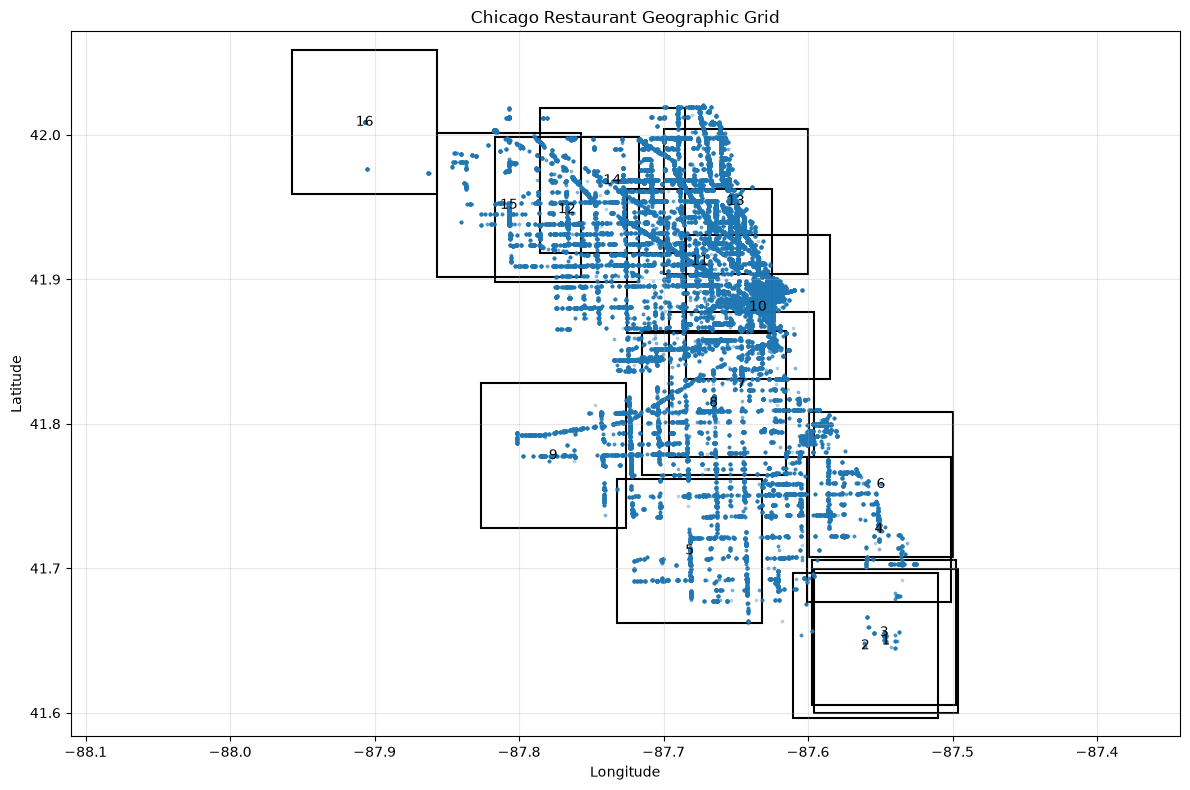

In [49]:

import matplotlib.pyplot as plt
import matplotlib.patches as patches

# Keep records with valid geographic region IDs
map_df = df.dropna(
    subset=["Latitude", "Longitude", "Geo_Region_ID"]
).copy()

# Get the unique geographic cells
grid_cells = (
    map_df.groupby("Geo_Grid_ID")
    .agg(
        Latitude=("Latitude", "first"),
        Longitude=("Longitude", "first"),
        Geo_Region_ID=("Geo_Region_ID", "first"),
        Inspection_Count=("Restaurant_ID", "size")
    )
    .reset_index()
)

fig, ax = plt.subplots(figsize=(12, 8))

# Approximate grid-cell width and height in degrees
cell_width = 0.1
cell_height = 0.1

for _, row in grid_cells.iterrows():
    rect = patches.Rectangle(
        (row["Longitude"] - cell_width / 2,
         row["Latitude"] - cell_height / 2),
        cell_width,
        cell_height,
        fill=False,
        linewidth=1.5
    )
    ax.add_patch(rect)

    ax.text(
        row["Longitude"],
        row["Latitude"],
        str(int(row["Geo_Region_ID"])),
        ha="center",
        va="center",
        fontsize=10
    )

# Show individual restaurant locations
ax.scatter(
    map_df["Longitude"],
    map_df["Latitude"],
    s=3,
    alpha=0.25
)

ax.set_title("Chicago Restaurant Geographic Grid")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_aspect("equal", adjustable="datalim")
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

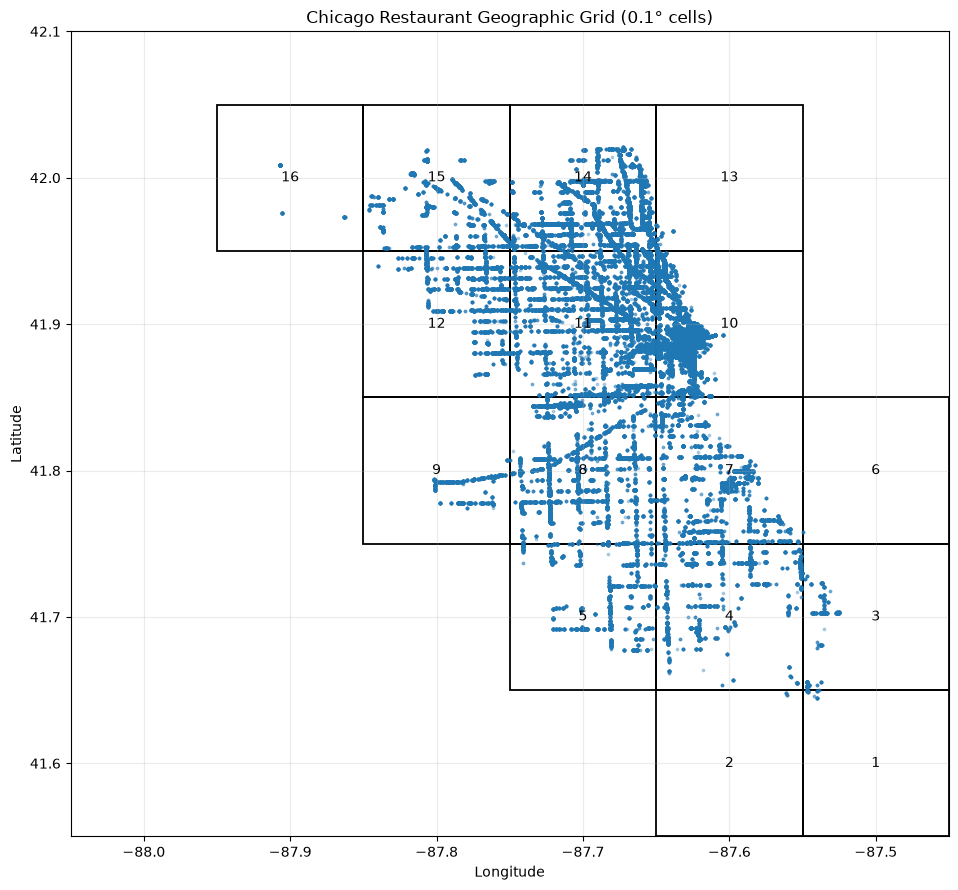

In [50]:

import matplotlib.pyplot as plt
import matplotlib.patches as patches
import pandas as pd

# Keep rows with valid coordinates and grid IDs
map_df = df.dropna(
    subset=["Latitude", "Longitude", "Geo_Grid_ID", "Geo_Region_ID"]
).copy()

# Get one row per grid cell
grid_cells = (
    map_df.groupby(["Geo_Grid_ID", "Geo_Region_ID"])
    .agg(
        Inspection_Count=("Restaurant_ID", "size")
    )
    .reset_index()
)

# Recover the rounded grid-center coordinates from Geo_Grid_ID
grid_cells[["Grid_Latitude", "Grid_Longitude"]] = (
    grid_cells["Geo_Grid_ID"]
    .str.split("_", expand=True)
    .astype(float)
)

fig, ax = plt.subplots(figsize=(12, 9))

cell_size = 0.1

for _, row in grid_cells.iterrows():
    lat = row["Grid_Latitude"]
    lon = row["Grid_Longitude"]

    # Correct boundaries: +/- 0.05 degrees from rounded center
    rect = patches.Rectangle(
        (lon - cell_size / 2, lat - cell_size / 2),
        cell_size,
        cell_size,
        fill=False,
        edgecolor="black",
        linewidth=1.3
    )
    ax.add_patch(rect)

    ax.text(
        lon,
        lat,
        str(int(row["Geo_Region_ID"])),
        ha="center",
        va="center",
        fontsize=10
    )

# Plot inspection locations
ax.scatter(
    map_df["Longitude"],
    map_df["Latitude"],
    s=3,
    alpha=0.3
)

ax.set_title("Chicago Restaurant Geographic Grid (0.1° cells)")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_xlim(-88.05, -87.45)
ax.set_ylim(41.55, 42.10)
ax.grid(alpha=0.25)
ax.set_aspect("equal", adjustable="box")

plt.tight_layout()
plt.show()

In [51]:
df.head()

,Risk,Inspection Date,Inspection Type,Results,Violations,Location,Restaurant_ID,Inspection_Sequence,Days_Since_Previous_Inspection,Inspection_Year,Inspection_Month,Inspection_Quarter,Inspection_DayOfWeek,Violations_Text_Available,Violation_Count,Latitude,Longitude,Geo_Grid_ID,Geo_Region_ID
0,Risk 1 (High),2010-06-15,Canvass,Pass,32. FOOD AND NON-FOOD CONTACT SURFACES PROPERL...,"(41.88075715864721, -87.6347092983425)",1,0,NaN,2010,6,2,Tuesday,1,5,41.880757,-87.634709,41.9_-87.6,10
1,Risk 1 (High),2011-02-15,Canvass,Pass,32. FOOD AND NON-FOOD CONTACT SURFACES PROPERL...,"(41.88075715864721, -87.6347092983425)",1,1,245.0,2011,2,1,Tuesday,1,5,41.880757,-87.634709,41.9_-87.6,10
2,Risk 1 (High),2012-03-19,Canvass,Pass w/ Conditions,4. SOURCE OF CROSS CONTAMINATION CONTROLLED I....,"(41.88075715864721, -87.6347092983425)",1,2,398.0,2012,3,1,Monday,1,4,41.880757,-87.634709,41.9_-87.6,10
3,Risk 1 (High),2013-07-19,Canvass,Pass,32. FOOD AND NON-FOOD CONTACT SURFACES PROPERL...,"(41.88075715864721, -87.6347092983425)",1,3,487.0,2013,7,3,Friday,1,3,41.880757,-87.634709,41.9_-87.6,10
4,Risk 1 (High),2014-04-18,Canvass,Pass,32. FOOD AND NON-FOOD CONTACT SURFACES PROPERL...,"(41.88075715864721, -87.6347092983425)",1,4,273.0,2014,4,2,Friday,1,4,41.880757,-87.634709,41.9_-87.6,10


In [52]:
print(df.columns.tolist())

['Risk', 'Inspection Date', 'Inspection Type', 'Results', 'Violations', 'Location', 'Restaurant_ID', 'Inspection_Sequence', 'Days_Since_Previous_Inspection', 'Inspection_Year', 'Inspection_Month', 'Inspection_Quarter', 'Inspection_DayOfWeek', 'Violations_Text_Available', 'Violation_Count', 'Latitude', 'Longitude', 'Geo_Grid_ID', 'Geo_Region_ID']


In [53]:

import pandas as pd

# Load your friend's CSV into a separate dataframe
FILE_PATH = "../data/processed/inspection_data_with_violation_scores.csv"

violation_df = pd.read_csv(FILE_PATH, low_memory=False)

print("File loaded successfully!")
print("Shape:", violation_df.shape)

File loaded successfully!
Shape: (156985, 17)


In [54]:

print("Columns in violation_df:\n")

for i, column in enumerate(violation_df.columns, start=1):
    print(f"{i}. {column}")

Columns in violation_df:

1. Risk
2. Inspection Date
3. Inspection Type
4. Results
5. Violations
6. Location
7. Restaurant_ID
8. Inspection_Sequence
9. Days_Since_Previous_Inspection
10. Number_of_Violations
11. Average_Violation_Score
12. Mapped_Violation_Count
13. Unmatched_Violation_Count
14. Compliant_Positive_Count
15. Administrative_Count
16. Hazard_Count
17. Unclear_Count


In [55]:

current_columns = set(df.columns)
friend_columns = set(violation_df.columns)

new_columns = sorted(friend_columns - current_columns)
common_columns = sorted(friend_columns & current_columns)

print("New columns to investigate:")
print(new_columns)

print("\nColumns already present in df:")
print(common_columns)

New columns to investigate:
['Administrative_Count', 'Average_Violation_Score', 'Compliant_Positive_Count', 'Hazard_Count', 'Mapped_Violation_Count', 'Number_of_Violations', 'Unclear_Count', 'Unmatched_Violation_Count']

Columns already present in df:
['Days_Since_Previous_Inspection', 'Inspection Date', 'Inspection Type', 'Inspection_Sequence', 'Location', 'Restaurant_ID', 'Results', 'Risk', 'Violations']


In [56]:

keys = ["Restaurant_ID", "Inspection_Sequence"]

# Check whether both dataframes contain the required keys
print("Keys present in df:", all(k in df.columns for k in keys))
print("Keys present in violation_df:",
      all(k in violation_df.columns for k in keys))

# Check duplicate key combinations
print("\nDuplicate keys in df:")
print(df.duplicated(subset=keys).sum())

print("\nDuplicate keys in violation_df:")
print(violation_df.duplicated(subset=keys).sum())

# Compare row counts
print("\ndf shape:", df.shape)
print("violation_df shape:", violation_df.shape)

Keys present in df: True
Keys present in violation_df: True

Duplicate keys in df:
0

Duplicate keys in violation_df:
0

df shape: (156985, 19)
violation_df shape: (156985, 17)


In [57]:

# Identify matching inspection keys
df_keys = df[keys].drop_duplicates()
friend_keys = violation_df[keys].drop_duplicates()

key_comparison = df_keys.merge(
    friend_keys,
    on=keys,
    how="outer",
    indicator=True
)

print(key_comparison["_merge"].value_counts())

_merge
both          156985
left_only          0
right_only         0
Name: count, dtype: int64


In [58]:

# List of new features to add
new_features = [
    "Administrative_Count",
    "Average_Violation_Score",
    "Compliant_Positive_Count",
    "Hazard_Count",
    "Mapped_Violation_Count",
    "Number_of_Violations",
    "Unclear_Count",
    "Unmatched_Violation_Count"
]

# Select merge keys and new features
features_to_merge = violation_df[
    ["Restaurant_ID", "Inspection_Sequence"] + new_features
]

# Merge the new features into the existing dataframe
df = df.merge(
    features_to_merge,
    on=["Restaurant_ID", "Inspection_Sequence"],
    how="left",
    validate="one_to_one"
)

print("Merge completed successfully!")
print("Updated dataframe shape:", df.shape)

Merge completed successfully!
Updated dataframe shape: (156985, 27)


In [59]:

print("Updated columns:")
print(df.columns.tolist())

print("\nNew feature preview:")
display(
    df[
        [
            "Restaurant_ID",
            "Inspection_Sequence",
            "Number_of_Violations",
            "Average_Violation_Score",
            "Mapped_Violation_Count",
            "Hazard_Count",
            "Administrative_Count",
            "Compliant_Positive_Count",
            "Unclear_Count",
            "Unmatched_Violation_Count"
        ]
    ].head(10)
)

print("\nMissing values in new features:")
print(df[new_features].isna().sum())

Updated columns:
['Risk', 'Inspection Date', 'Inspection Type', 'Results', 'Violations', 'Location', 'Restaurant_ID', 'Inspection_Sequence', 'Days_Since_Previous_Inspection', 'Inspection_Year', 'Inspection_Month', 'Inspection_Quarter', 'Inspection_DayOfWeek', 'Violations_Text_Available', 'Violation_Count', 'Latitude', 'Longitude', 'Geo_Grid_ID', 'Geo_Region_ID', 'Administrative_Count', 'Average_Violation_Score', 'Compliant_Positive_Count', 'Hazard_Count', 'Mapped_Violation_Count', 'Number_of_Violations', 'Unclear_Count', 'Unmatched_Violation_Count']

New feature preview:


,Restaurant_ID,Inspection_Sequence,Number_of_Violations,Average_Violation_Score,Mapped_Violation_Count,Hazard_Count,Administrative_Count,Compliant_Positive_Count,Unclear_Count,Unmatched_Violation_Count
0,1,0,5,0.600000,5,0,2,3,0,0
1,1,1,5,0.400000,5,0,1,4,0,0
2,1,2,4,0.000000,4,0,1,3,0,0
3,1,3,3,0.666667,3,0,1,2,0,0
4,1,4,4,0.250000,4,0,2,2,0,0
5,1,5,3,0.333333,3,0,2,1,0,0
6,1,6,5,0.600000,5,0,3,2,0,0
7,1,7,5,0.600000,5,0,2,3,0,0
8,1,8,2,0.000000,2,0,1,1,0,0
9,1,9,5,1.400000,5,2,1,2,0,0



Missing values in new features:
Administrative_Count         0
Average_Violation_Score      0
Compliant_Positive_Count     0
Hazard_Count                 0
Mapped_Violation_Count       0
Number_of_Violations         0
Unclear_Count                0
Unmatched_Violation_Count    0
dtype: int64


In [60]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 156985 entries, 0 to 156984
Data columns (total 27 columns):
 #   Column                          Non-Null Count   Dtype         
---  ------                          --------------   -----         
 0   Risk                            156985 non-null  str           
 1   Inspection Date                 156985 non-null  datetime64[us]
 2   Inspection Type                 156985 non-null  str           
 3   Results                         156985 non-null  str           
 4   Violations                      156985 non-null  str           
 5   Location                        156985 non-null  str           
 6   Restaurant_ID                   156985 non-null  int64         
 7   Inspection_Sequence             156985 non-null  int64         
 8   Days_Since_Previous_Inspection  134649 non-null  float64       
 9   Inspection_Year                 156985 non-null  int32         
 10  Inspection_Month                156985 non-null  int32         
 11

In [61]:
# OUTPUT_PATH = "../data/processed/restaurant_final_cleaned.csv"

# df.to_csv(
#     OUTPUT_PATH,
#     index=False
# )

# print("File saved successfully!")
# print("Saved to:", OUTPUT_PATH)

In [62]:
df.isna().sum()

Risk                                  0
Inspection Date                       0
Inspection Type                       0
Results                               0
Violations                            0
Location                              0
Restaurant_ID                         0
Inspection_Sequence                   0
Days_Since_Previous_Inspection    22336
Inspection_Year                       0
Inspection_Month                      0
Inspection_Quarter                    0
Inspection_DayOfWeek                  0
Violations_Text_Available             0
Violation_Count                       0
Latitude                              0
Longitude                             0
Geo_Grid_ID                           0
Geo_Region_ID                         0
Administrative_Count                  0
Average_Violation_Score               0
Compliant_Positive_Count              0
Hazard_Count                          0
Mapped_Violation_Count                0
Number_of_Violations                  0


In [63]:
df['Days_Since_Previous_Inspection'] = df['Days_Since_Previous_Inspection'].fillna(0)

In [64]:
df.isna().sum()

Risk                              0
Inspection Date                   0
Inspection Type                   0
Results                           0
Violations                        0
Location                          0
Restaurant_ID                     0
Inspection_Sequence               0
Days_Since_Previous_Inspection    0
Inspection_Year                   0
Inspection_Month                  0
Inspection_Quarter                0
Inspection_DayOfWeek              0
Violations_Text_Available         0
Violation_Count                   0
Latitude                          0
Longitude                         0
Geo_Grid_ID                       0
Geo_Region_ID                     0
Administrative_Count              0
Average_Violation_Score           0
Compliant_Positive_Count          0
Hazard_Count                      0
Mapped_Violation_Count            0
Number_of_Violations              0
Unclear_Count                     0
Unmatched_Violation_Count         0
dtype: int64

In [66]:
df['Results'].value_counts()

Results
Pass                  84213
Fail                  37666
Pass w/ Conditions    34450
No Entry                581
Not Ready                44
Out of Business          31
Name: count, dtype: int64

In [67]:

# Keep only inspections with a clear pass/fail outcome
valid_results = ["Pass", "Pass w/ Conditions", "Fail"]

rows_before = len(df)

df = df[df["Results"].isin(valid_results)].copy()

rows_after = len(df)

# Map outcomes to a binary target
df["Results"] = df["Results"].map({
    "Pass": 0,
    "Pass w/ Conditions": 0,
    "Fail": 1
}).astype(int)

print("Rows before filtering:", rows_before)
print("Rows after filtering:", rows_after)
print("Rows removed:", rows_before - rows_after)

print("\nTarget distribution:")
print(df["Results"].value_counts().sort_index())

print("\nTarget distribution (%):")
print(
    (df["Results"].value_counts(normalize=True)
     .sort_index() * 100).round(2)
)


Rows before filtering: 156985
Rows after filtering: 156329
Rows removed: 656

Target distribution:
Results
0    118663
1     37666
Name: count, dtype: int64

Target distribution (%):
Results
0    75.91
1    24.09
Name: proportion, dtype: float64


In [70]:
df.isna().sum()

Risk                              0
Inspection Date                   0
Inspection Type                   0
Results                           0
Violations                        0
Location                          0
Restaurant_ID                     0
Inspection_Sequence               0
Days_Since_Previous_Inspection    0
Inspection_Year                   0
Inspection_Month                  0
Inspection_Quarter                0
Inspection_DayOfWeek              0
Violations_Text_Available         0
Violation_Count                   0
Latitude                          0
Longitude                         0
Geo_Grid_ID                       0
Geo_Region_ID                     0
Administrative_Count              0
Average_Violation_Score           0
Compliant_Positive_Count          0
Hazard_Count                      0
Mapped_Violation_Count            0
Number_of_Violations              0
Unclear_Count                     0
Unmatched_Violation_Count         0
dtype: int64

In [71]:
OUTPUT_PATH = "../data/processed/restaurant_final_cleaned2.csv"

df.to_csv(
    OUTPUT_PATH,
    index=False
)

print("File saved successfully!")
print("Saved to:", OUTPUT_PATH)

File saved successfully!
Saved to: ../data/processed/restaurant_final_cleaned2.csv
